# Movie Genre Prediction with a Multi-Layer Perceptron

Issue #37 · Multi-label classification · Steps 1–12

## Data and goal

Source: `data/features/10_genre_features.csv` from the shared Week 5 Features folder. A movie may have multiple genre labels.

## 1. Select input features and genre targets

Use 15 numeric or Boolean features and original language as inputs. Predict 20 binary genre columns; a movie can have more than one genre. Exclude `id` and all genre labels from the inputs, plus post-release revenue and popularity. Long text and names need additional encoding, so this first model uses their prepared counts and indicators. Remove rows with no recorded genre rather than treating missing labels as confirmed negatives.

In [16]:
from pathlib import Path
import pandas as pd

# Find the CSV whether VS Code starts the notebook in the project root
# or in the notebook's own folder.
relative_path = Path("data/features/10_genre_features.csv")
csv_path = next(
    (folder / relative_path for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / relative_path).exists()),
    None,
)

if csv_path is None:
    raise FileNotFoundError(
        "Put 10_genre_features.csv in the project's data/features folder."
    )

movies = pd.read_csv(csv_path, low_memory=False)

# These 20 columns are the answers the model should predict.
genre_columns = [
    "Drama", "Crime", "Comedy", "Action", "Thriller",
    "Adventure", "Science Fiction", "Animation", "Family",
    "Romance", "Mystery", "Music", "Horror", "Fantasy",
    "Documentary", "War", "Western", "History", "Foreign", "TV Movie",
]

# Start with movie information that is usable around release time.
numeric_columns = [
    "release_year", "release_month", "log_budget", "runtime",
    "cast_size", "crew_size", "company_count", "country_count",
    "spoken_languages_count", "keyword_count", "title_word_count",
    "overview_word_count", "has_collection", "has_director",
    "title_differs_from_original",
]
categorical_columns = ["original_language"]
feature_columns = numeric_columns + categorical_columns

# Check that the CSV has the columns we expect and that genre labels are 0 or 1.
required_columns = feature_columns + genre_columns
missing_columns = sorted(set(required_columns) - set(movies.columns))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if not movies[genre_columns].isin([0, 1]).all().all():
    raise ValueError("Some genre labels are not 0 or 1.")

# Rows with no recorded genre cannot teach the model a known genre.
has_recorded_genre = movies[genre_columns].sum(axis=1) > 0
X = movies.loc[has_recorded_genre, feature_columns].copy()
y = movies.loc[has_recorded_genre, genre_columns].astype(int).copy()

print(f"CSV: {csv_path}")
print(f"All movies: {len(movies):,}")
print(f"Movies with no recorded genre removed: {(~has_recorded_genre).sum():,}")
print(f"Movies available for modeling: {len(X):,}")
print(f"Input features ({len(feature_columns)}): {feature_columns}")
print(f"Genre targets ({len(genre_columns)}): {genre_columns}")
print("\nNumber of movies in each genre:")
print(y.sum().sort_values(ascending=False).to_string())

CSV: /Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/data/features/10_genre_features.csv
All movies: 45,433
Movies with no recorded genre removed: 2,442
Movies available for modeling: 42,991
Input features (16): ['release_year', 'release_month', 'log_budget', 'runtime', 'cast_size', 'crew_size', 'company_count', 'country_count', 'spoken_languages_count', 'keyword_count', 'title_word_count', 'overview_word_count', 'has_collection', 'has_director', 'title_differs_from_original', 'original_language']
Genre targets (20): ['Drama', 'Crime', 'Comedy', 'Action', 'Thriller', 'Adventure', 'Science Fiction', 'Animation', 'Family', 'Romance', 'Mystery', 'Music', 'Horror', 'Fantasy', 'Documentary', 'War', 'Western', 'History', 'Foreign', 'TV Movie']

Number of movies in each genre:
Drama              20244
Comedy             13176
Thriller            7619
Romance             6730
Action              6592
Horror              4671
Crime               4304
Documentary         3

## 2. Prepare numerical and categorical features

Treat zero log budgets as unknown, convert Boolean inputs to 0/1, fill missing numeric values with medians, scale numeric inputs, and one-hot encode original language. The preprocessing pipeline is defined here and fitted on training movies only after the split.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Keep the original X from Step 1 intact.
X_model = X.copy()

# The three true/false columns become 1.0/0.0 along with the other numbers.
X_model[numeric_columns] = X_model[numeric_columns].astype(float)

# In this dataset, budget 0 often stands for an unknown budget.
# Treat it as missing so the model does not assume every 0 means a real $0 budget.
zero_budget_count = X_model["log_budget"].eq(0).sum()
X_model["log_budget"] = X_model["log_budget"].mask(
    X_model["log_budget"].eq(0)
)

numeric_preprocessing = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

categorical_preprocessing = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_preprocessing, numeric_columns),
    ("language", categorical_preprocessing, categorical_columns),
])

print(f"Zero budgets treated as missing: {zero_budget_count:,}")
print("\nColumns with the most missing values:")
print(X_model.isna().sum().sort_values(ascending=False).head(8).to_string())
print("\nPreprocessing pipeline created. It has not been fitted yet.")

Zero budgets treated as missing: 34,169

Columns with the most missing values:
log_budget           34169
runtime                182
release_year            29
release_month           29
original_language       10
cast_size                0
crew_size                0
company_count            0

Preprocessing pipeline created. It has not been fitted yet.


## 3. Create training, validation, and test splits

Use a fixed seed for an 80/10/10 split. Fit preprocessing on training movies; only transform validation and test movies. Reserve the test set for one final evaluation after selecting a model from validation results.

In [18]:
import numpy as np
from sklearn.model_selection import train_test_split

# First reserve 20% of movies for validation and testing.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X_model, y, test_size=0.20, random_state=42
)

# Divide that reserved group equally: 10% validation, 10% test.
X_validation, X_test, y_validation, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=42
)

# Confirm that each movie is in exactly one group.
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)

# Learn fill values, scaling, and language categories from training movies only.
X_train_ready = preprocessor.fit_transform(X_train)

# Apply those same learned rules to validation and test movies.
X_validation_ready = preprocessor.transform(X_validation)
X_test_ready = preprocessor.transform(X_test)

assert np.isfinite(X_train_ready).all()
assert np.isfinite(X_validation_ready).all()
assert np.isfinite(X_test_ready).all()

print(f"Training movies:   {len(X_train):,} ({len(X_train) / len(X_model):.0%})")
print(f"Validation movies: {len(X_validation):,} ({len(X_validation) / len(X_model):.0%})")
print(f"Test movies:       {len(X_test):,} ({len(X_test) / len(X_model):.0%})")
print(f"Total model inputs after preprocessing: {X_train_ready.shape[1]}")

# Check that even the less common genres appear in all three groups.
genre_counts = pd.DataFrame({
    "training": y_train.sum(),
    "validation": y_validation.sum(),
    "test": y_test.sum(),
})
print("\nFive least common genres across the splits:")
print(genre_counts.sum(axis=1).sort_values().head(5).index.to_list())
print(genre_counts.loc[genre_counts.sum(axis=1).sort_values().head(5).index])

Training movies:   34,392 (80%)
Validation movies: 4,299 (10%)
Test movies:       4,300 (10%)
Total model inputs after preprocessing: 101

Five least common genres across the splits:
['TV Movie', 'Western', 'War', 'History', 'Music']
          training  validation  test
TV Movie       614          73    79
Western        813         116   113
War           1049         132   141
History       1127         133   138
Music         1289         142   166


## 4. Train multiple MLP configurations

Train four MLPs using different hidden-layer layouts and learning rates. All use Adam, ReLU, batch size 256, and seed 42. Each reached the 80-iteration cap, so the convergence warnings must be considered when interpreting the scores.

In [19]:
import time
from sklearn.neural_network import MLPClassifier

# Each tuple describes the size of the hidden layers.
# For example, (64, 32) means two hidden layers with 64 and 32 neurons.
configurations = [
    {"name": "one_layer_32",  "layers": (32,),    "learning_rate": 0.001},
    {"name": "one_layer_64",  "layers": (64,),    "learning_rate": 0.001},
    {"name": "two_layers",   "layers": (64, 32), "learning_rate": 0.001},
    {"name": "slower_rate",  "layers": (64, 32), "learning_rate": 0.0003},
]

trained_models = {}
training_summary = []

for config in configurations:
    print(f"Training {config['name']}...")
    start_time = time.perf_counter()

    model = MLPClassifier(
        hidden_layer_sizes=config["layers"],
        learning_rate_init=config["learning_rate"],
        activation="relu",
        solver="adam",
        batch_size=256,
        max_iter=80,
        tol=0.001,
        n_iter_no_change=8,
        random_state=42,
    )

    model.fit(X_train_ready, y_train)

    trained_models[config["name"]] = model
    training_summary.append({
        "model": config["name"],
        "hidden_layers": str(config["layers"]),
        "learning_rate": config["learning_rate"],
        "iterations": model.n_iter_,
        "final_training_loss": model.loss_,
        "training_seconds": round(time.perf_counter() - start_time, 1),
    })

pd.DataFrame(training_summary)

Training one_layer_32...


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Training one_layer_64...


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Training two_layers...


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Training slower_rate...


/Users/kevinphon/Desktop/DS-ML Project Fall Semester/css-dsml-fall2027/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,hidden_layers,learning_rate,iterations,final_training_loss,training_seconds
0,one_layer_32,"(32,)",0.0010,80,5.022079,9.1
1,one_layer_64,"(64,)",0.0010,80,4.946679,12.4
2,two_layers,"(64, 32)",0.0010,80,4.849186,15.6
3,slower_rate,"(64, 32)",0.0003,80,4.967447,9.8


## 5. Compare validation precision, recall, and F1

Compare every configuration on the same validation movies. Micro scores combine all movie–genre decisions; macro F1 gives each genre equal weight. Count movies with no predicted genre to reveal low prediction coverage. Use these validation results to choose the model in step 6.

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

validation_rows = []

for config in configurations:
    name = config["name"]
    model = trained_models[name]

    # Predict the 20 genre labels for validation movies only.
    predicted_genres = model.predict(X_validation_ready)
    assert predicted_genres.shape == y_validation.shape

    validation_rows.append({
        "model": name,
        "hidden_layers": str(config["layers"]),
        "learning_rate": config["learning_rate"],
        "micro_precision": precision_score(
            y_validation, predicted_genres, average="micro", zero_division=0
        ),
        "micro_recall": recall_score(
            y_validation, predicted_genres, average="micro", zero_division=0
        ),
        "micro_f1": f1_score(
            y_validation, predicted_genres, average="micro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_validation, predicted_genres, average="macro", zero_division=0
        ),
        "movies_with_no_predicted_genre": (
            predicted_genres.sum(axis=1) == 0
        ).sum(),
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values("micro_f1", ascending=False)
    .reset_index(drop=True)
)

print(validation_results.to_string(
    index=False,
    formatters={"learning_rate": lambda value: f"{value:.4f}"},
    float_format=lambda value: f"{value:.3f}"
))

       model hidden_layers learning_rate  micro_precision  micro_recall  micro_f1  macro_f1  movies_with_no_predicted_genre
  two_layers      (64, 32)        0.0010            0.647         0.229     0.338     0.148                            1492
one_layer_32         (32,)        0.0010            0.641         0.218     0.326     0.124                            1502
 slower_rate      (64, 32)        0.0003            0.658         0.215     0.324     0.130                            1598
one_layer_64         (64,)        0.0010            0.645         0.215     0.323     0.135                            1591


## 6. Choose the model using validation results

Use micro F1 as the main comparison score from step 5. Then try a few probability cutoffs for that model on the validation set. A lower cutoff may find more real genres, but it can also add incorrect predictions. Choose both the model and cutoff before looking at test results.

In [21]:
# Step 5 already sorted the configurations by validation micro F1.
best_model_name = validation_results.loc[0, "model"]
best_model = trained_models[best_model_name]

# The decision threshold is another setting chosen using validation data only.
validation_probabilities = best_model.predict_proba(X_validation_ready)
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
threshold_rows = []

for threshold in thresholds:
    predictions = (validation_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "micro_precision": precision_score(
            y_validation, predictions, average="micro", zero_division=0
        ),
        "micro_recall": recall_score(
            y_validation, predictions, average="micro", zero_division=0
        ),
        "micro_f1": f1_score(
            y_validation, predictions, average="micro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_validation, predictions, average="macro", zero_division=0
        ),
        "movies_with_no_predicted_genre": int((predictions.sum(axis=1) == 0).sum()),
    })

threshold_results = pd.DataFrame(threshold_rows)
chosen_row = threshold_results.sort_values(
    ["micro_f1", "macro_f1"], ascending=False
).iloc[0]
best_threshold = float(chosen_row["threshold"])

print(f"Model chosen from validation: {best_model_name}")
print(f"Threshold chosen from validation: {best_threshold:.2f}")
print("\nThreshold comparison (validation set only):")
print(threshold_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

Model chosen from validation: two_layers
Threshold chosen from validation: 0.25

Threshold comparison (validation set only):
 threshold  micro_precision  micro_recall  micro_f1  macro_f1  movies_with_no_predicted_genre
     0.200            0.385         0.572     0.460     0.293                               0
     0.250            0.435         0.495     0.463     0.272                               3
     0.300            0.485         0.424     0.452     0.243                              54
     0.350            0.531         0.365     0.433     0.221                             273
     0.400            0.574         0.313     0.405     0.194                             639
     0.450            0.618         0.269     0.374     0.172                            1058
     0.500            0.647         0.229     0.338     0.148                            1492


## 7. Evaluate the chosen model once on the test set

The model and threshold were fixed in step 6. Use the held-out test movies now for the final precision, recall, and F1 scores. Do not use these scores to change the model.

In [22]:
# This is the final held-out evaluation. Do not tune settings on these results.
test_probabilities = best_model.predict_proba(X_test_ready)
test_predictions = (test_probabilities >= best_threshold).astype(int)
assert test_predictions.shape == y_test.shape

test_results = {
    "micro_precision": precision_score(
        y_test, test_predictions, average="micro", zero_division=0
    ),
    "micro_recall": recall_score(
        y_test, test_predictions, average="micro", zero_division=0
    ),
    "micro_f1": f1_score(y_test, test_predictions, average="micro", zero_division=0),
    "macro_precision": precision_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, test_predictions, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(y_test, test_predictions, average="macro", zero_division=0),
}

print(f"Final test results: {best_model_name}, threshold {best_threshold:.2f}")
for metric, value in test_results.items():
    print(f"{metric}: {value:.3f}")
print(f"Test movies with no predicted genre: {(test_predictions.sum(axis=1) == 0).sum():,} / {len(X_test):,}")

Final test results: two_layers, threshold 0.25
micro_precision: 0.437
micro_recall: 0.491
micro_f1: 0.463
macro_precision: 0.343
macro_recall: 0.276
macro_f1: 0.270
Test movies with no predicted genre: 9 / 4,300


## 8. Compare model configurations

This chart uses the step 5 validation scores at the default 0.50 cutoff. It shows how the four layer and learning-rate settings compared before the final model was chosen.

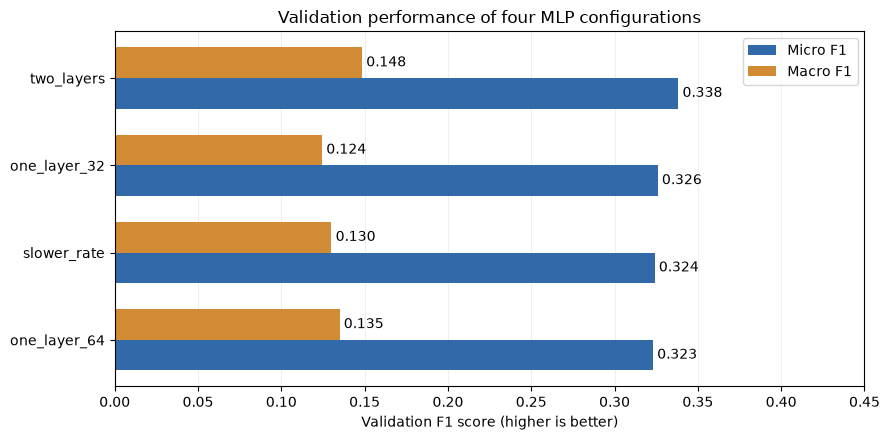

In [23]:
import matplotlib.pyplot as plt

comparison = validation_results.sort_values("micro_f1")
positions = np.arange(len(comparison))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))
micro_bars = ax.barh(
    positions - bar_height / 2, comparison["micro_f1"],
    height=bar_height, label="Micro F1", color="#3269a8"
)
macro_bars = ax.barh(
    positions + bar_height / 2, comparison["macro_f1"],
    height=bar_height, label="Macro F1", color="#d18b35"
)
ax.set_yticks(positions, comparison["model"])
ax.set_xlim(0, 0.45)
ax.set_xlabel("Validation F1 score (higher is better)")
ax.set_title("Validation performance of four MLP configurations")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.bar_label(micro_bars, fmt="%.3f", padding=3)
ax.bar_label(macro_bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()

## 9. Show F1 for each genre

Use the chosen model’s final test predictions. A separate F1 score for every genre shows where the model works better or worse; the number of actual examples gives context for rare genres.

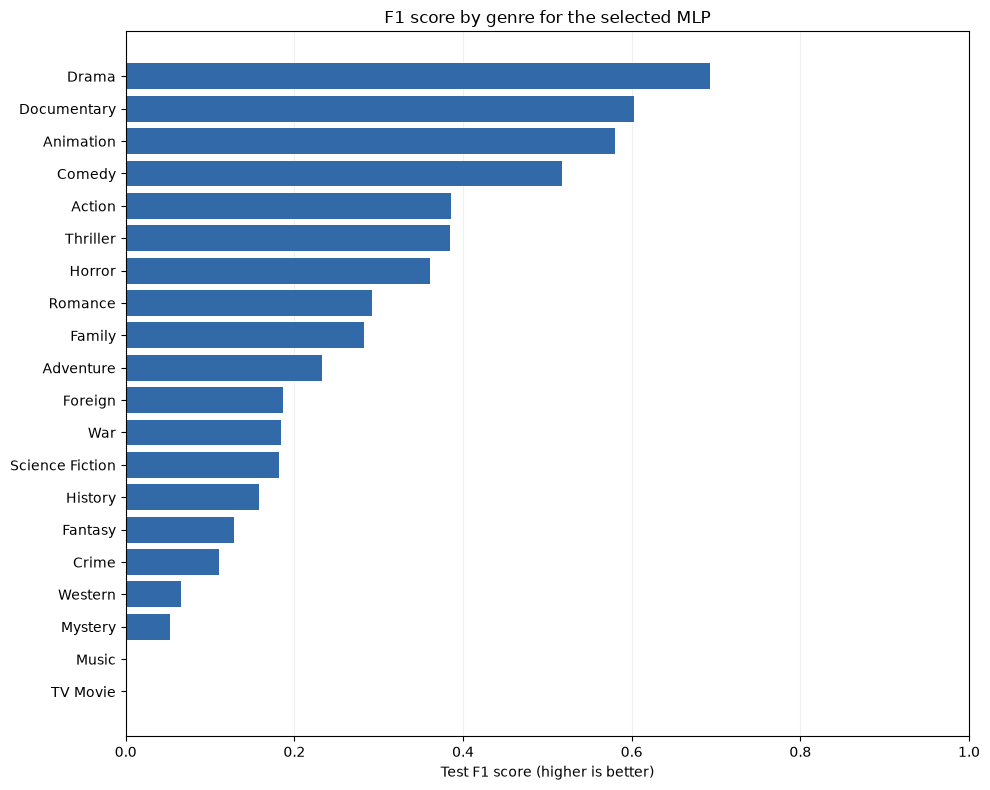

          genre  test_movies_with_genre  precision  recall    f1
       TV Movie                      79      0.000   0.000 0.000
          Music                     166      0.000   0.000 0.000
        Mystery                     243      0.318   0.029 0.053
        Western                     113      0.500   0.035 0.066
          Crime                     407      0.217   0.074 0.110
        Fantasy                     237      0.267   0.084 0.128
        History                     138      0.288   0.109 0.158
Science Fiction                     334      0.331   0.126 0.182
            War                     141      0.485   0.113 0.184
        Foreign                     161      0.250   0.149 0.187
      Adventure                     353      0.370   0.170 0.233
         Family                     270      0.411   0.215 0.282
        Romance                     652      0.290   0.294 0.292
         Horror                     470      0.355   0.368 0.361
       Thriller          

In [24]:
per_genre_results = pd.DataFrame({
    "genre": genre_columns,
    "test_movies_with_genre": y_test.sum(axis=0).to_numpy(),
    "precision": precision_score(
        y_test, test_predictions, average=None, zero_division=0
    ),
    "recall": recall_score(y_test, test_predictions, average=None, zero_division=0),
    "f1": f1_score(y_test, test_predictions, average=None, zero_division=0),
}).sort_values("f1")

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(per_genre_results["genre"], per_genre_results["f1"], color="#3269a8")
ax.set_xlim(0, 1)
ax.set_xlabel("Test F1 score (higher is better)")
ax.set_title("F1 score by genre for the selected MLP")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

print(per_genre_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))

## 10. Show one movie prediction

Use one held-out movie as a simple inference example. The title is shown only to identify the movie; it was not a model input. The model uses the same preprocessing and threshold chosen earlier.

In [25]:
from IPython.display import display

# Pick the first test movie with at least one predicted genre for a readable demo.
# This sample choice is only for the example; all test movies count in the metrics.
example_position = int(np.flatnonzero(test_predictions.sum(axis=1) > 0)[0])
example_input = X_test.iloc[[example_position]]
example_index = example_input.index[0]
example_probabilities = best_model.predict_proba(
    preprocessor.transform(example_input)
)
example_prediction = (example_probabilities >= best_threshold).astype(int)[0]
example_actual = y_test.loc[example_index].to_numpy()

print(f"Movie: {movies.loc[example_index, 'title']}")
print("Selected input fields:")
display(example_input[[
    "release_year", "release_month", "original_language", "runtime",
    "log_budget", "cast_size", "crew_size", "keyword_count"
]])
print("Predicted genres:", [genre for genre, value in zip(genre_columns, example_prediction) if value])
print("Actual recorded genres:", [genre for genre, value in zip(genre_columns, example_actual) if value])

Movie: Back to Stay
Selected input fields:


,release_year,release_month,original_language,runtime,log_budget,cast_size,crew_size,keyword_count
27591,2011.0,8.0,en,95.0,NaN,4.0,1.0,1.0


Predicted genres: ['Drama', 'Comedy']
Actual recorded genres: ['Drama', 'Comedy']


## 11. Optional chart: how the threshold changes validation F1

This chart shows the validation tradeoff used in step 6. It helps explain why the final cutoff differs from the default 0.50.

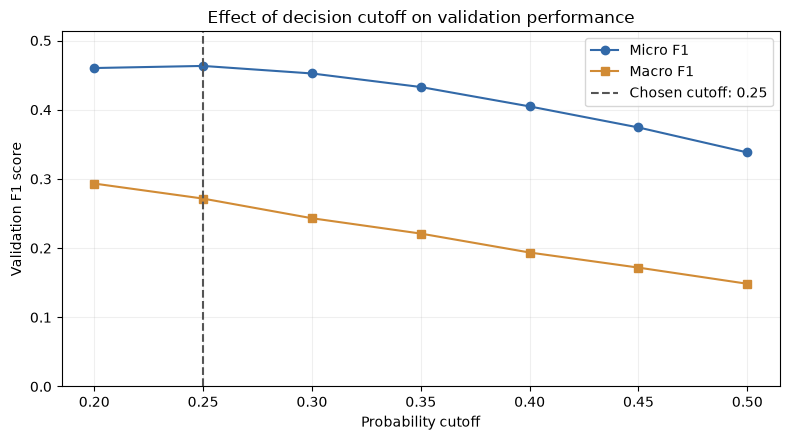

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(threshold_results["threshold"], threshold_results["micro_f1"],
        marker="o", label="Micro F1", color="#3269a8")
ax.plot(threshold_results["threshold"], threshold_results["macro_f1"],
        marker="s", label="Macro F1", color="#d18b35")
ax.axvline(best_threshold, color="#555555", linestyle="--",
           label=f"Chosen cutoff: {best_threshold:.2f}")
ax.set_xlabel("Probability cutoff")
ax.set_ylabel("Validation F1 score")
ax.set_title("Effect of decision cutoff on validation performance")
ax.set_xticks(threshold_results["threshold"])
ax.set_ylim(0, max(threshold_results[["micro_f1", "macro_f1"]].max()) + 0.05)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 12. Explain the results

Use the per-genre test scores to name the easier and harder genres. More training examples may help, but support alone does not prove why a genre is difficult. State the low recall and convergence warnings as limitations.

In [27]:
strongest_genres = per_genre_results.sort_values("f1", ascending=False).head(3)
hardest_genres = per_genre_results.sort_values("f1").head(3)

print("Three highest test F1 scores:")
print(strongest_genres[["genre", "test_movies_with_genre", "f1"]].to_string(
    index=False, float_format=lambda value: f"{value:.3f}"
))
print("\nThree lowest test F1 scores:")
print(hardest_genres[["genre", "test_movies_with_genre", "f1"]].to_string(
    index=False, float_format=lambda value: f"{value:.3f}"
))
print(f"\nOverall test micro F1: {test_results['micro_f1']:.3f}; macro F1: {test_results['macro_f1']:.3f}")
print("All four models hit the 80-iteration limit, so convergence is a limitation.")

Three highest test F1 scores:
      genre  test_movies_with_genre    f1
      Drama                    2029 0.693
Documentary                     426 0.603
  Animation                     187 0.580

Three lowest test F1 scores:
   genre  test_movies_with_genre    f1
TV Movie                      79 0.000
   Music                     166 0.000
 Mystery                     243 0.053

Overall test micro F1: 0.463; macro F1: 0.270
All four models hit the 80-iteration limit, so convergence is a limitation.
